# KQC JunctionTest2 — SQUID test-pad arrays (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/junction_test2.py` (class `JunctionTest2`, default parameters, chip name "CTest";
© IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/junction_test2.py`; spec `docs/designs/kqc/test_chips.md`, one
notebook per chip). A process / test chip: six `JunctionTestPads` arrays of SQUIDs (Manhattan junctions in the source, Quantcore trilayer SQUIDs here) with stepped junction widths, small (80 µm²) and large (130 µm²) loops. No qubits or resonators.

This notebook **rebuilds** the chip on the Quantcore PDK — not a replica. We distribute the rebuild under GPL-3.0.
The chip is one KQC chip PCell, so most steps of a circuit notebook (launchers, routes, LOM, FEM, iterate) have
nothing to act on here; each says so.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm; the KQC chip cell is placed with `frames_enabled=[]`, so the Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "CTest") replaces KQC's frame |
| pattern | `JunctionTest2.build()` | the same KQC cell with its default parameters (except the junction type and the large-loop start width, see the PDK section), so its own `build()` draws every polygon and label |
| substrate | silicon (KQC simulation default) | sapphire 650 µm, εr 10.25 (it changes nothing here: there is no circuit to simulate) |
| junctions | KQC Manhattan SQUIDs | Quantcore trilayer SQUIDs (see the PDK section) |
| cheese | KQC's whole-area ground grid (`with_grid`, 5 µm holes on a 10 µm step, in KQC's mask builds); the cell keeps it off its structures with `ground_grid_avoidance` | The original wins: `with_grid=True` draws KQC's whole-area grid round the cell, and the cell's `ground_grid_avoidance` keeps it off its six test-pad arrays (fab view, Fab 2), so no PDK band is added. |
| placement | as drawn by KQC | Centred (50 µm off in x, at the 50 µm tolerance): no shift. |

**Kept exactly:** the chip is KQC's `JunctionTest2` chip PCell placed once in a 10 × 10 mm Designer chip, with
`frames_enabled=[]`, so KQC's `build()` draws every polygon and label but not its ChipFrame; the Designer chip
draws the Quantcore die frame instead. Fab 2 XORs it with a stand-alone KQC build, which keeps KQC's frame.

**Simplified:** nothing; there are no internal ports or circuit to rebuild element by element.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the empty die, the KQC chip cell placed (and the design saved), the pad-rule check, then views of its parts: the test-pad arrays and one test SQUID. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `junction_test2.v1.ipynb`; both save the same `junction_test2.json`.

This chip is one KQC PCell with no circuit to simulate: the LOM step is the table of the test SQUIDs' R_n and L_J,
the Results step the sweep against the PDK's R_n window; Simulate says why it does not apply; Check and Fab run
as in the v1.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/junction_test2/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

On this chip the FEM switches change nothing (it has no sim groups); they are kept so that every design notebook
starts the same way.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc/test_chips")                 # design JSON + final snapshots
STEPS = Path("build/snapshots/junction_test2")  # step-by-step snapshots (build/ is not kept in the repo)
# Quantcore trilayer SQUIDs in every test pad; the large-loop sweep starts at the PDK minimum finger (0.1 µm)
PDK_SQUIDS = {"junction_type": "Quantcore Squid", "junction_width_large": 0.10}

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip uses the junction rule (its test SQUIDs), the frame, the cheese rule and the fab layer map.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The test SQUIDs from the PDK rule.** Every test SQUID is a Quantcore SQUID (`junction_type="Quantcore Squid"` on
the chip cell): KQC's stepped `junction_width` is the straight finger, the bent finger stays at the PDK 0.6 µm.
KQC's large-loop sweep starts at 0.08 µm, below the PDK minimum finger (0.1 µm), so it starts at 0.10 µm here (the
0.03 µm step is kept); the small-loop sweep keeps 0.15 µm + 0.01 µm steps. `PDK_SQUIDS` (Setup) holds these two
cell parameters; LOM 1 tabulates the R_n and L_J they give.

# Design: the layout, one segment at a time

The whole chip is one KQC PCell, `JunctionTest2`: its `build()` draws six arrays of SQUID test pads with stepped junction widths in one piece. The layout
cannot be split into segments without redrawing that cell (a redesign, not a rebuild), so the segments are the
empty die, the cell placed (and the design saved there, before any picture of it, as in the v1), the pad check, and
then views of its parts with the numbers that make them. KQC's ground grid (`with_grid`) is drawn in every build: Design 1 (the empty die) and Design 2 (the chip) are one
build each; the views after them are zooms of the second build (no rebuild).

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame (device ID CTest), KQC's grid (`with_grid`) |
| 2 | the whole chip: KQC's `JunctionTest2` cell at the origin with KQC's frames off, the centring check, the save |
| 3 | bond pads: none on this chip (the pad-rule check) |
| 4 | a view: the test-pad arrays |
| 5 | a view: one test SQUID between its pads |

## Design 1 · The empty die and its frame

`Designer(...)` starts the 10 × 10 mm chip with the name "CTest" (the device ID). The original wins: `with_grid=True` draws KQC's whole-area grid round the cell, and the cell's `ground_grid_avoidance` keeps it off its six test-pad arrays (fab view, Fab 2), so no PDK band is added.

The picture is the die with nothing on it but the Quantcore frame (L dicing markers on 1000/0, 3 × 3 alignment grids on
1001/0, the chip boundary on 100/0). With `with_grid` KQC's grid is part of every build.

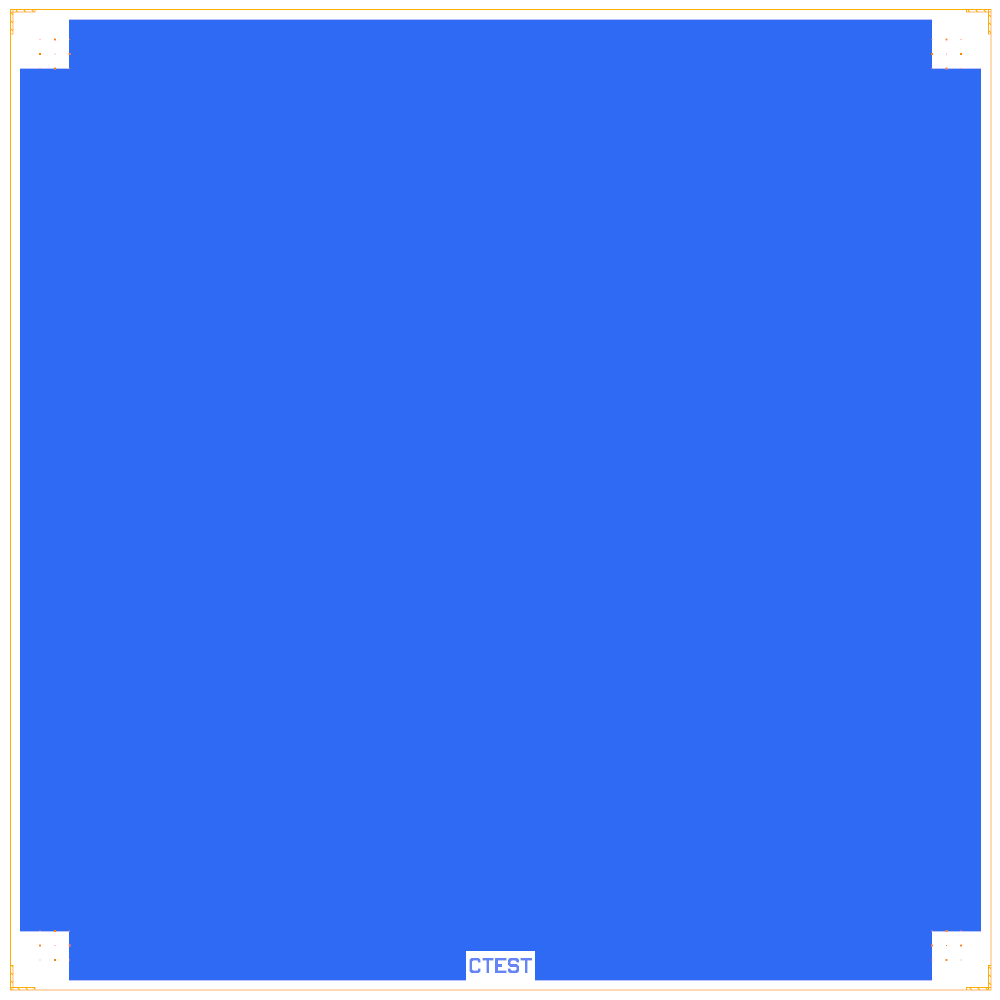

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/junction_test2/s1_die.png')

In [5]:
d = Designer("junction_test2", box=(0, 0, 10000, 10000), chip={"name_chip": "CTest", "with_grid": True}, live=LIVE)
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "s1_die.png", **CHIP)

## Design 2 · The chip cell: `JunctionTest2`, placed once, and the save

The whole design is one instance: KQC's `JunctionTest2` chip PCell at the chip origin with `frames_enabled=[]`, so KQC draws
no `ChipFrame` and the Designer chip draws the Quantcore die frame (L dicing markers on 1000/0, 3 × 3 alignment
grids on 1001/0, the chip boundary on 100/0). `center_in_die` then checks that the cell's content sits centred in the
die and moves the cell if it is more than 50 µm off. Centred (50 µm off in x, at the 50 µm tolerance): no shift. Then the design is saved with `save_design`, which compares it with the file it replaces (the previous run's):
it should say *same design*. `junction_test2.json` is what the DRC, the fab export and `qcc` read.

The save comes before any picture of the chip, as in the v1. The picture is the whole chip; the table lists the
cell's own parameters (KQC `get_schema`) with the value this design passes where it passes one. `X0, Y0` (the cell's
origin after the centring) place the views below.

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/kqc/test_chips/junction_test2.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer junction_test2: 1 instances, 0 routes, live=False> → examples\designs\kqc\test_chips\junction_test2.json


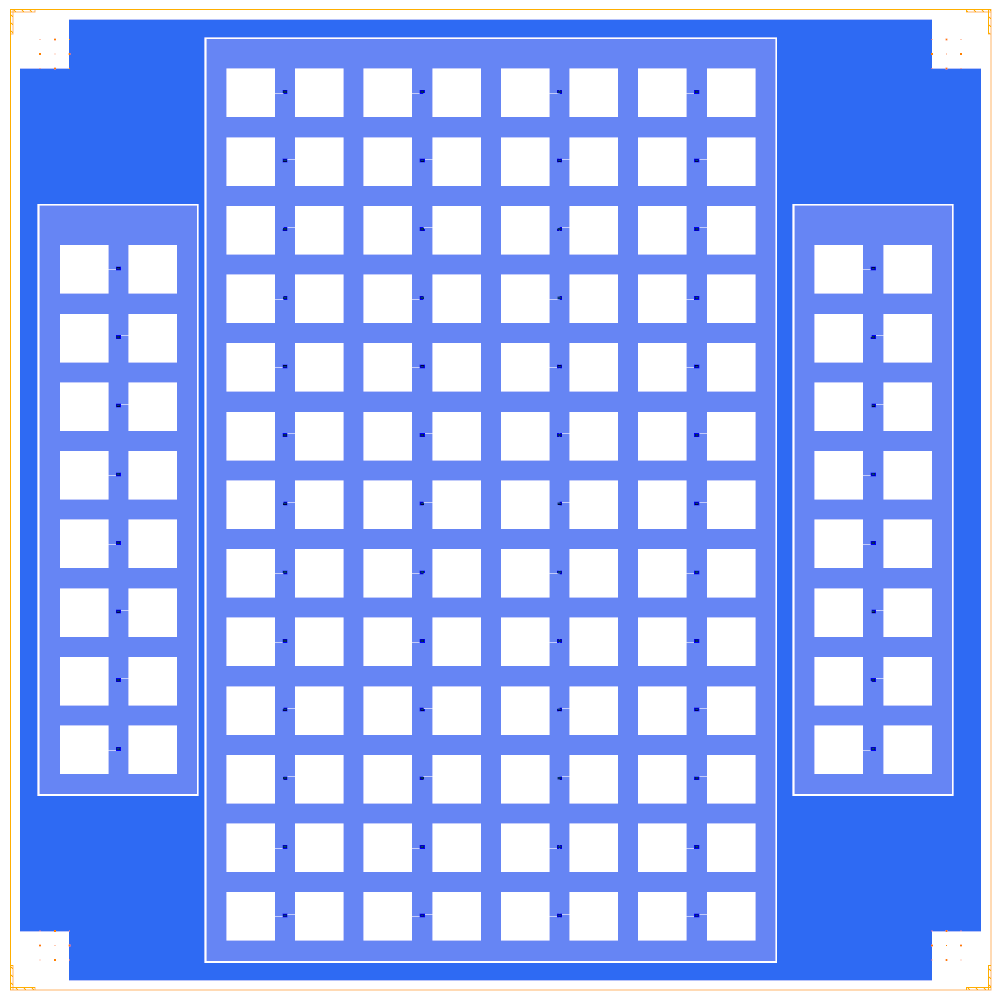

**On the chip so far:** 0 pads · 0 qubits · 1 other components · 0 routes · 0 declared couplings. **This step added** 1 component(s) `CHIP`.

**`JunctionTest2`** parameters:

| parameter | default | this design | meaning |
|---|---|---|---|
| `pad_width` | 500 | (default) | Pad width |
| `junctions_horizontal` | True | (default) | Horizontal (True) or vertical (False) junctions |
| `small_loop_area` | 80 | (default) | Test SQUIDs small loop area |
| `large_loop_area` | 130 | (default) | Test SQUIDs large loop area |
| `junction_width_small` | 0.15 | (default) | Test SQUIDs Junction finger width starting value (small loop) |
| `junction_width_large` | 0.08 | 0.1 | Test SQUIDs Junction finger width starting value (large loop) |
| `junction_width_step_increment_small` | 0.01 | (default) | Junction finger width step increment (small loop) |
| `junction_width_step_increment_large` | 0.03 | (default) | Junction finger width step increment (large loop) |
| `pads_loop` | ['large', 'large', 'small', 'small', 'small', 'large'] | (default) | Select large or small loop area for each central test pad |
| `marker_types` | ['Marker Standard', 'Marker Standard', 'Marker Standard', 'M… | (default) | Marker type for each chip corner, clockwise starting from lower left |
| `junction_type` | Manhattan | Quantcore Squid | Junction Type |
| `a` | 10 | (default) | Width of center conductor |
| `b` | 6 | (default) | Width of gap |
| `n` | 64 | (default) | Number of points on turns |
| `r` | 100 | (default) | Turn radius |
| `margin` | 5 | (default) | Margin of the protection layer |
| `face_ids` | ['1t1', '2b1', '1b1', '2t1'] | (default) | Chip face IDs list |
| `display_name` |  | (default) | Name displayed in GUI (empty for default) |
| `protect_opposite_face` | False | (default) | Add ground grid avoidance on opposing face |
| `opposing_face_id_groups` | [['1t1', '2b1']] | (default) | Opposing face ID groups (list of lists) |
| `duplicate_face_ids` | [] | (default) | Duplicate face IDs (list of lists), where the first face of each group is copied into other faces |
| `duplicate_layers` | ['base_metal_gap', 'base_metal_gap_wo_grid', 'base_metal_add… | (default) | Layers (list), which are copied into other faces when duplicate_face_ids are given |
| `etch_opposite_face` | False | (default) | Etch avoidance shaped gap on the opposite face too |
| `etch_opposite_face_margin` | 5 | (default) | Margin of the opposite face etch shape |
| `_epr_show` | False | (default) | Show geometry related to EPR simulation, if available |
| `_epr_cross_section_cut` | False | (default) | Show EPR cross section cuts, if available |
| `_epr_counter` | 0 | (default) | Internal counter to enable EPR preview |
| `area_height` | 1900 | (default) | Area height |
| `area_width` | 1300 | (default) | Area width |
| `pad_spacing` | 200 | (default) | Spacing between different pad pairs |
| `only_pads` | False | (default) | Only produce pads, no junctions |
| `pad_configuration` | 2-port | (default) | Pad configuration |
| `junction_width_steps` | [0, 0] | (default) | Automatically generate junction widths [start, step] |
| `junction_widths` | [] | (default) | Optional junction widths for individual junctions |
| `junction_test_pads_type` | Junction Test Pads Simple | (default) | Type of junction test pads |
| `mirror_squid` | False | (default) | Mirror SQUID by its Y axis |
| `finger_overshoot` | 1.0 | (default) | Length of fingers after the junction. |
| `include_base_metal_gap` | True | (default) | Include base metal gap layer |
| `shadow_margin` | 1.0 | (default) | Shadow layer margin near the the pads |
| `compact_geometry` | False | (default) | Compact geometry for metal addition. |
| `separate_junctions` | True | (default) | Junctions to separate layer |
| `offset_compensation` | 0 | (default) | Junction lead offset from junction width |
| `mirror_offset` | False | (default) | Move the junction lead offset to the other lead |
| `finger_overlap` | 0.2 | (default) | Length of fingers inside the pads |
| `single_junction` | False | (default) | Disable the second junction |

In [6]:
d.add("CHIP", "JunctionTest2", at=(0, 0), frames_enabled=[], **PDK_SQUIDS)   # KQC chip PCell, no KQC frame
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "junction_test2.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, STEPS / "1_chip.png", **CHIP)
X0, Y0 = d.data["instances"]["CHIP"]["place"]["at"]   # the cell's origin (after the centring shift): the views use it
display(Markdown(pcell_params_md("JunctionTest2", d.data["instances"]["CHIP"]["params"])))

## Design 3 · Bond pads: none on this chip

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge
(`edge="auto"` on a pad instance). This chip has no pad instances and no launchers (the table below is empty): any probe pads belong to KQC's drawing of the cell, so the rule has nothing to place.

There are no routes either (no RF lines on this chip); the one component is the chip cell of Design 2.

In [7]:
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

## Design 4 · A view: the test-pad arrays

Six `JunctionTestPads` arrays (KQC source): arrays 1 and 6 at the sides, 6000 µm tall, arrays 2–5 in the centre,
9400 µm tall. Each holds pad pairs one above the other every `pad_width` + `pad_spacing` = 700 µm (500 µm pads 200 µm
apart), so 8 or 13 SQUIDs per array, and `pads_loop` picks each array's loop: large (130 µm²) for arrays 1, 2 and 6,
small (80 µm²) for 3–5. The picture shows the top rows of the four centre arrays, a SQUID between the pads of each
pair.

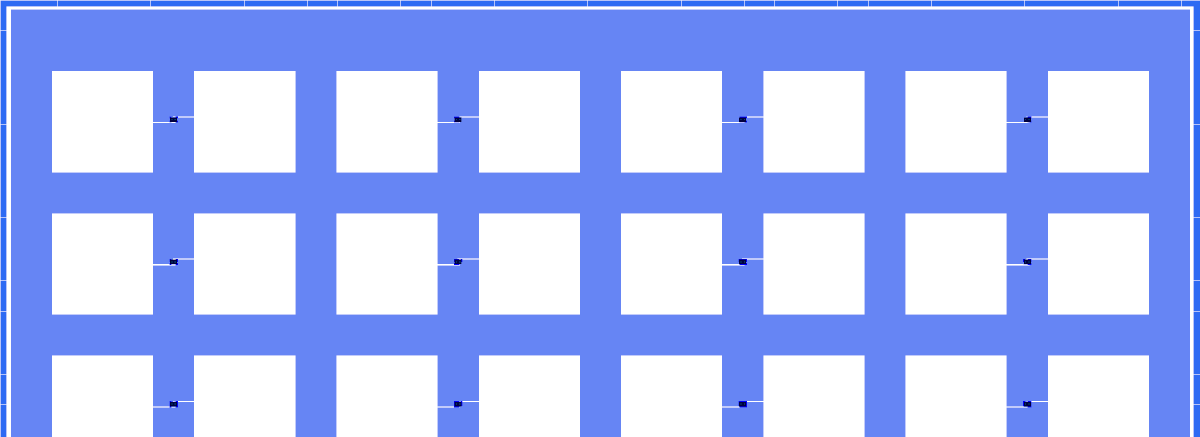

In [8]:
snap(d, STEPS / "s4_arrays.png", box=(X0 + 1950, Y0 + 7600, X0 + 7850, Y0 + 9750), size=(1200, 437), width=600);

## Design 5 · A view: one test SQUID

Between the two pads of a pair sits one Quantcore trilayer SQUID (`junction_type = "Quantcore Squid"`, from
`PDK_SQUIDS`): KQC's stepped `junction_width` is the straight finger (2/0), the bent finger (4/0) stays at the PDK
0.6 µm, the loop area is the array's. LOM 1 tabulates the R_n and L_J of every step. The picture zooms on the SQUID
of the top pair of array 2 (the box is read off the v1 run's pad picture: adjust it if the SQUID is not in it).

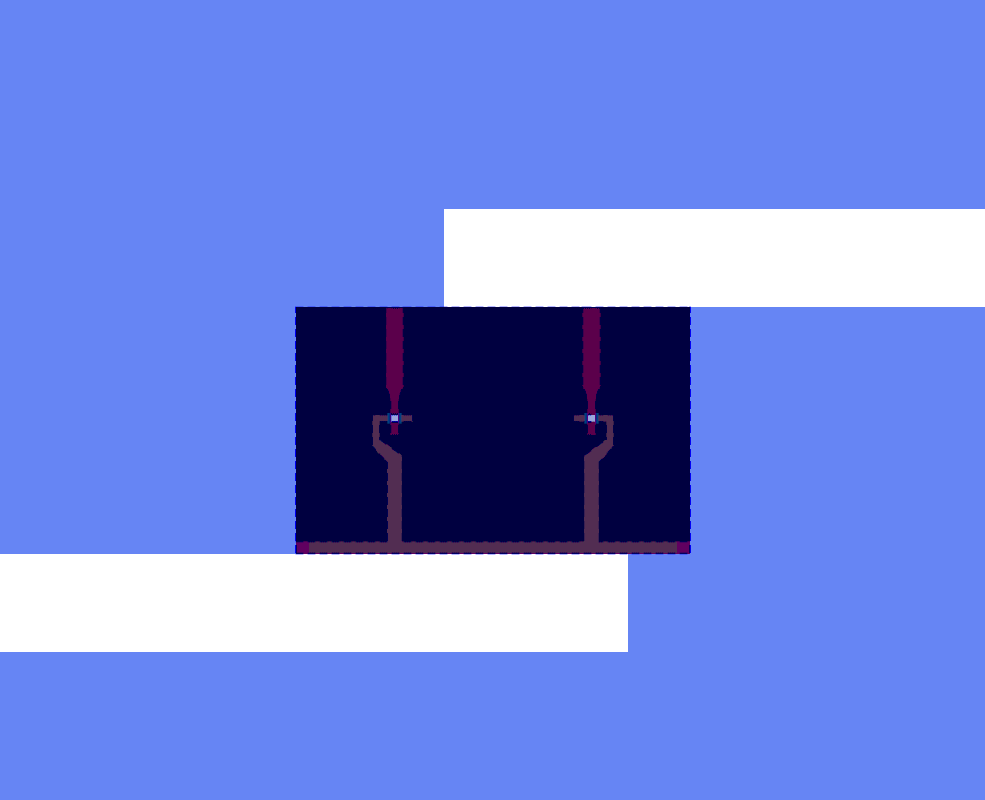

In [9]:
snap(d, STEPS / "s5_squid.png", box=(X0 + 2760, Y0 + 9130, X0 + 2840, Y0 + 9195), size=(985, 800), width=420);

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** 0 errors and 4 `frame_keepout` warnings: the chip cell's bounding box spans the 10 × 10 mm chip and so overlaps the four corner marker areas; nothing the cell draws sits on the dicing L's or the alignment grids (the frame-corner snapshot in Fab 2 shows it). No PDK design warning; `pdk_report` gives KQC's grid ("the original design's own"), the content 50 µm off in x and no junction types (the test SQUIDs sit inside the cell's `JunctionTestPads`, which the report does not count).

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit from the components' LOM models. No component here has one (the
chip is a process test structure), so the netlist is ground only.

In [ ]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

# LOM: no modes; the junction table instead

## LOM 1 · The test SQUIDs: R_n and L_J per array

There are no modes to simulate. What this chip measures is each test SQUID's R_n (at room temperature, on a probe
station), so the useful numbers are the R_n and L_J the PDK junction rule gives each stepped finger: two junctions
in parallel per SQUID (`circuit.bridges.junction_from_fingers`: Nb Δ = 1.4 meV, R_n·A = 13.5 kΩ·µm² assumed). The
last column counts the SQUIDs inside the PDK's 40–50 kΩ window.

In [ ]:
from quantcore_circuits.circuit.bridges import junction_from_fingers
from quantcore_circuits.pdk import get_pdk
from kqcircuits.chips.junction_test2 import JunctionTest2

PROC = get_pdk().junction                         # Nb Δ 1.4 meV, R_n·A 13.5 kΩ·µm² (assumed), bent finger 0.6 µm


def squid_table(squids):
    p = JunctionTest2()
    heights = [6000, 9400, 9400, 9400, 9400, 6000]
    start = {"small": squids.get("junction_width_small", p.junction_width_small),
             "large": squids.get("junction_width_large", p.junction_width_large)}
    step = {"small": p.junction_width_step_increment_small, "large": p.junction_width_step_increment_large}
    idx = {"small": 0, "large": 0}
    lo, hi = PROC.rn_target_kohm
    rows = ["| array | loop | SQUIDs | straight finger (µm) | R_n per SQUID (kΩ) | L_J per SQUID (nH) | in 40–50 kΩ |",
            "|---|---|---|---|---|---|---|"]
    total = 0
    for j, (loop, h) in enumerate(zip(p.pads_loop, heights), start=1):
        n = int(h // (p.pad_spacing + p.pad_width))
        ws = [start[loop] + (idx[loop] + k) * step[loop] for k in range(n)]
        idx[loop] += n
        v = [junction_from_fingers(w, PROC.bent_finger_um, n=2) for w in ws]
        inside = sum(lo <= x.rn_kohm <= hi for x in v)
        total += inside
        rows.append(f"| {j} | {loop} ({p.large_loop_area if loop == 'large' else p.small_loop_area:g} µm²) | {n} | "
                    f"{ws[0]:.2f} … {ws[-1]:.2f} | {v[0].rn_kohm:.1f} … {v[-1].rn_kohm:.1f} | "
                    f"{v[0].lj_nH:.2f} … {v[-1].lj_nH:.2f} | {inside} |")
    return "\n".join(rows), total


table, n_in = squid_table(PDK_SQUIDS)
display(Markdown(table + f"\n\n**{n_in} SQUIDs inside the window.**"))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: nothing to export

The design has no sim groups (a process structure has nothing for a C-matrix, eigenmode or driven solve), so the
export below writes no FEM job, and the switches at the top change nothing here.

In [ ]:
jobs = export_sims(DESIGN)                       # one job per sim group: this design has none
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

# Results: the sweep against the PDK R_n window

## Results 1 · Feedback: one change of the sweep

There is no simulation to re-run, but the sweep is a design choice: it decides how many SQUIDs land in the PDK
window. Start the large-loop sweep at 0.40 µm instead of 0.10 µm (the same 0.03 µm step) and count again. The chip
itself is not rebuilt (the change is on the table's parameters only).

In [ ]:
table2, n_in2 = squid_table(dict(PDK_SQUIDS, junction_width_large=0.40))
display(Markdown(f"**Large-loop start 0.10 → 0.40 µm:** {n_in} → {n_in2} SQUIDs in the 40–50 kΩ window\n\n" + table2))

## Results 2 · Iterate: scan the large-loop start

The feedback repeated: every large-loop start from the PDK minimum finger (0.10 µm) to 0.40 µm in 0.01 µm steps,
counted against the 40–50 kΩ window, the best start kept (the smallest of equal counts). The arithmetic behind the
answer: two 0.6 µm bent fingers in parallel give R_n ≈ 11.25 kΩ·µm / w (LOM 1: 112.5 kΩ at 0.10 µm), so the window
takes straight fingers of 0.225–0.281 µm, a band narrower than two 0.03 µm steps: whatever the start, at most two
large-loop SQUIDs fall inside it, and the step (`junction_width_step_increment_large`) is the knob that adds more. The
chip is not rebuilt; a change is a new `PDK_SQUIDS` and a new design.

In [ ]:
starts = [round(0.10 + 0.01 * k, 2) for k in range(31)]      # 0.10 … 0.40 µm, the PDK minimum finger first
counts = {w: squid_table(dict(PDK_SQUIDS, junction_width_large=w))[1] for w in starts}
best = max(counts, key=lambda w: (counts[w], -w))
rows = ["| large-loop start (µm) | SQUIDs in 40–50 kΩ |", "|---|---|"] + [f"| {w:.2f} | {n} |" for w, n in counts.items()]
display(Markdown("\n".join(rows) + f"\n\n**Best start: {best:.2f} µm → {counts[best]} SQUIDs in the window** "
                 f"(this design: {PDK_SQUIDS['junction_width_large']:.2f} µm → {n_in})."))

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `junction_test2.json` (saved in Design 2) is the whole design: `qcc build
examples/designs/kqc/test_chips/junction_test2.json` rebuilds `build/junction_test2.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), the trilayer fingers 2/0 + 4/0 and spacer 50–53/0,
and the frame (100/0, 1000/0, 1001/0). In the v1 run: 1/0 200 995 polygons, 3/0 197 928, the trilayer fingers 2/0 and 4/0 68 polygons each, 50–53/0 272 each; cheese source `build`, 200 992 holes. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/test_chips/junction_test2.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The full chip; a zoom on the pad; the die frame's south-west corner (dicing L on 1000/0,
3 × 3 alignment grid on 1001/0); and one test-pad pair in the **fab view** (the mask from Fab 1). The chip
boundary 100/0 is drawn as an outline.

In [ ]:
X0, Y0 = d.data["instances"]["CHIP"]["place"]["at"]   # the cell's origin (after the centring shift)
show_snapshot(d, OUT / "junction_test2.png", box=(-100, -100, 10100, 10100))
show_snapshot(d, OUT / "junction_test2_pad.png", box=(X0 + 2000, Y0 + 8900, X0 + 3300, Y0 + 9700), size=(1300, 800), width=420)
show_snapshot(d, OUT / "junction_test2_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "junction_test2_fab.oas", OUT / "junction_test2_fab.png", box=(X0 + 2000, Y0 + 8900, X0 + 3300, Y0 + 9700), size=(1200, 1200), width=420);

**Reference: XOR with the source.** KQC's `JunctionTest2` built stand-alone (with KQC's own frame), XOR-ed layer by layer
with this build (`refpoints` and the `instance_names` label layer are annotation and are skipped). **The rebuild is
expected to differ** by design in the frame (KQC's ChipFrame vs the Quantcore die frame), the junction layers (Manhattan → trilayer SQUIDs) and the ground grid (KQC's stand-alone build has none). A
reference, not a pass/fail check.

In [ ]:
import klayout.db as kdb
from kqcircuits.chips.junction_test2 import JunctionTest2
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
ref_top = ref.create_cell("ref")
ref_top.insert(pya.DCellInstArray(JunctionTest2.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "junction_test2_kqc_original.oas"))
ly = kdb.Layout()
ly.read(str(d.out))
top = ly.top_cell()
by_name = {ly.get_info(i).name: i for i in ly.layer_indexes()}
rows, total = ["| layer | XOR area (µm²) |", "|---|---|"], 0.0
for li in ref.layer_indexes():
    info = ref.get_info(li)
    a = kdb.Region(ref_top.begin_shapes_rec(li)).merged()
    if a.is_empty() or info.name in ("refpoints", "instance_names"):
        continue
    b = kdb.Region(top.begin_shapes_rec(by_name[info.name])).merged() if info.name in by_name else kdb.Region()
    x = (a ^ b).area() * ref.dbu ** 2
    total += x
    rows.append(f"| {info.name} ({info.layer}/{info.datatype}) | {x:.3g} |")
display(Markdown("\n".join(rows) + f"\n\n**Total XOR area: {total:.3g} µm²**"))
snap_file(Path("build") / "junction_test2_kqc_original.oas", OUT / "junction_test2_kqc.png", box=(-100, -100, 10100, 10100), width=420);

**From the v1 run:** the XOR (3.2 × 10⁷ µm²) is KQC's frame and the junctions: KQC draws Manhattan SQUIDs (SIS layers 136/137/139, 3–4 × 10⁴ µm² each), the rebuild trilayer SQUIDs (base-metal addition 4.7 × 10⁴ µm²); the base etch differs by 8.73 × 10⁶ µm², the frame's 8.63 × 10⁶ plus the SQUID openings.

## Summary

| | |
|---|---|
| **matches the source** | the whole `JunctionTest2` cell (KQC's own `build()`); the junction sweep (from 0.10 µm on the large loops) |
| **differs (PDK)** | the Quantcore die frame instead of KQC's ChipFrame; the PDK fab layer map; KQC's grid round the arrays (200 992 holes in the v1 run); trilayer SQUIDs with the large-loop sweep from 0.10 µm (8 of the 68 SQUIDs in the 40–50 kΩ window in the v1 run) |
| **not applicable** | the pad rule (no pad instances), routes, LOM, FEM |
| **PDK design warnings** | as listed in Check 1 |
| **FEM** | no sim groups, no jobs |
| layout | the empty die, the chip cell placed (one KQC PCell, saved there), the pad check, then 2 view(s) of its parts (the test-pad arrays and one test SQUID); the saved JSON is the v1 notebook's |
| feedback | the large-loop start scanned against the PDK R_n window (Results 2); the design keeps 0.10 µm |
| open | the view boxes are read off the v1 run's pictures: adjust one if it misses its part |